# Regresion lineal para la calibracion de sensores

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import matplotlib.dates as mdates

## Informacion emparejada de la estacion LOGIA vs ESTACION LOCAL ESP32 SHC30
### DATOS
### fecha	estacion_temp	estacion_hum	sensor_temp	sensor_hum

In [15]:
df = pd.read_excel("../data/observaciones_02_03_2026.xlsx")

In [16]:
df.head()

,fecha,estacion_temp,estacion_hum,sensor_temp,sensor_hum,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48
0,2026-10-02 14:24:52,21.4,73.2,23.1,66.0,NaN,NaN,NaN,NaN,NaN,...,NaN,SUMMARY OUTPUT HUMEDAD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-02 14:29:52,21.3,73.6,24.1,64.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-02 14:34:52,21.2,73.1,23.9,63.0,NaN,NaN,NaN,NaN,NaN,...,NaN,Regression Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-10-02 14:39:52,21.5,72.5,23.5,65.0,NaN,NaN,NaN,NaN,NaN,...,NaN,Multiple R,0.781783,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-02 14:44:52,21.4,72.8,25.9,59.0,NaN,NaN,NaN,NaN,NaN,...,NaN,R Square,0.611185,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# ANALISIS DE REGRESIO DIA 02 OCT 2026
# PRIMER 02/10/26 14:00
# ULTIMA 03/10/26 14:00

In [18]:
fecha = df["fecha"].dropna()
estacion_temp = df["estacion_temp"].dropna()
sensor_temp = df["sensor_temp"].dropna()

In [19]:
n = len(estacion_temp)
sum_x_y = (sensor_temp * estacion_temp).sum()
sum_x = sensor_temp.sum()
sum_y = estacion_temp.sum()
sum_xsq = (sensor_temp * sensor_temp).sum()
sumx_sq = sum_x*sum_x

In [20]:
print(f"Observaciones (n): {n}")
print(f"SUM (X * Y): {sum_x_y}")
print(f"SUM (X): {sum_x}")
print(f"SUM (Y): {sum_y}")
print(f"SUM (sum_xsq): {sum_xsq}")
print(f"SUM (sumx_sq): {sumx_sq}")


Observaciones (n): 289
SUM (X * Y): 81417.48
SUM (X): 4746.799999999999
SUM (Y): 4866.5
SUM (sum_xsq): 80080.8
SUM (sumx_sq): 22532110.239999995


In [21]:
b = ((n*sum_x_y) - (sum_x * sum_y)) / ( (n * sum_xsq) - sumx_sq)
b

np.float64(0.7024226910447887)

In [22]:
a = (sum_y - (b * sum_x)) / n
a

np.float64(5.3018684088186765)

In [23]:
print(f"Pendiente {b}")
print(f"Intercepto {a}")

Pendiente 0.7024226910447887
Intercepto 5.3018684088186765


In [24]:
# Ecuacion de ajuste
# Y = a + bx
yp = (sensor_temp * b) + a

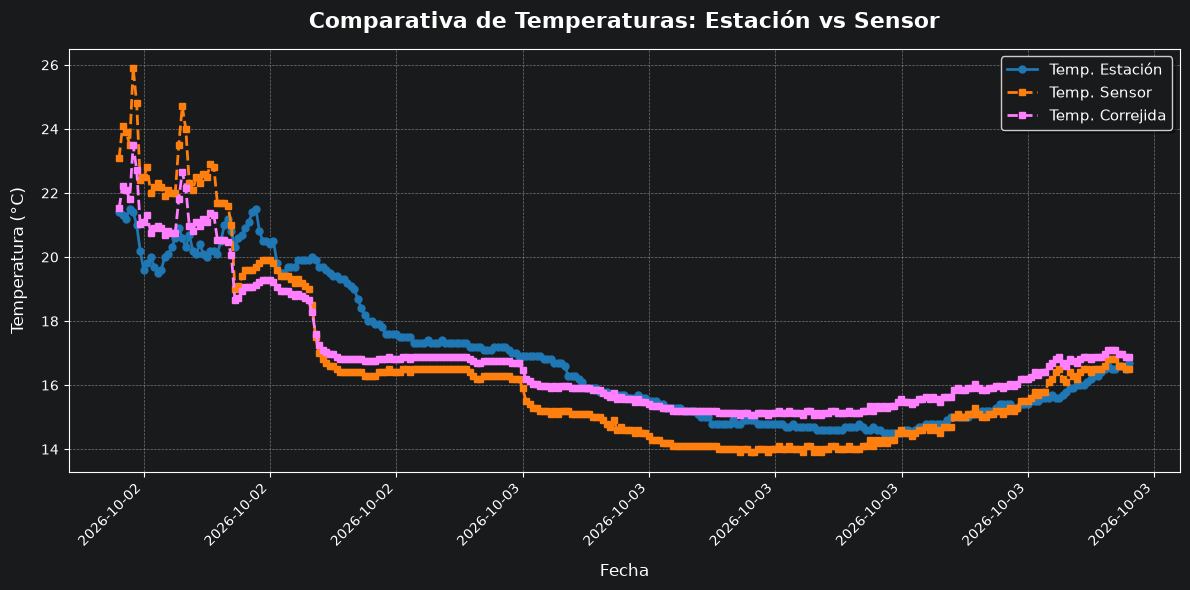

In [25]:
# 1. Configurar el tamaño y resolución de la figura
plt.figure(figsize=(12, 6), dpi=100)

# 2. Graficar la primera serie (Estación) con color y etiqueta definidos
plt.plot(
    fecha,
    estacion_temp,
    marker='o',          # Círculos
    markersize=5,
    linestyle='-',       # Línea continua
    linewidth=2,
    color='#1f77b4',     # Azul profesional
    label='Temp. Estación'
)

# 3. Graficar la segunda serie (Sensor) contrastando estilo
plt.plot(
    fecha,
    sensor_temp,
    marker='s',          # Cuadrados ('square') para diferenciar si se imprime en blanco y negro
    markersize=5,
    linestyle='--',      # Línea punteada
    linewidth=2,
    color='#ff7f0e',     # Naranja profesional
    label='Temp. Sensor'
)

plt.plot(
    fecha,
    yp,
    marker='s',          # Cuadrados ('square') para diferenciar si se imprime en blanco y negro
    markersize=5,
    linestyle='--',      # Línea punteada
    linewidth=2,
    color='#ff7fff',     # Naranja profesional
    label='Temp. Correjida'
)

# 4. Títulos y etiquetas de los ejes
plt.title('Comparativa de Temperaturas: Estación vs Sensor', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Fecha', fontsize=12, labelpad=10)
plt.ylabel('Temperatura (°C)', fontsize=12, labelpad=10) # Cambia la unidad si es necesario

# 5. Formatear el eje X para que las fechas sean legibles
# (Asume que 'fecha' contiene objetos datetime o pandas datetime)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d')) # Ajusta el formato según prefieras
plt.xticks(rotation=45, ha='right') # Rota las fechas 45 grados para que no se encimen

# 6. Cuadrícula y leyenda
plt.grid(True, linestyle='--', alpha=0.6) # Cuadrícula suave de fondo
plt.legend(loc='best', fontsize=11, frameon=True, shadow=True)

# 7. Ajustar automáticamente los márgenes para que nada se corte
plt.tight_layout()

# Mostrar la gráfica
plt.show()

In [28]:
ECM = (1/n) * math.pow((estacion_temp - yp).sum(),2)
print(f"Error cuadratico medio {ECM}")

Error cuadratico medio 1.3528445896263565e-27
